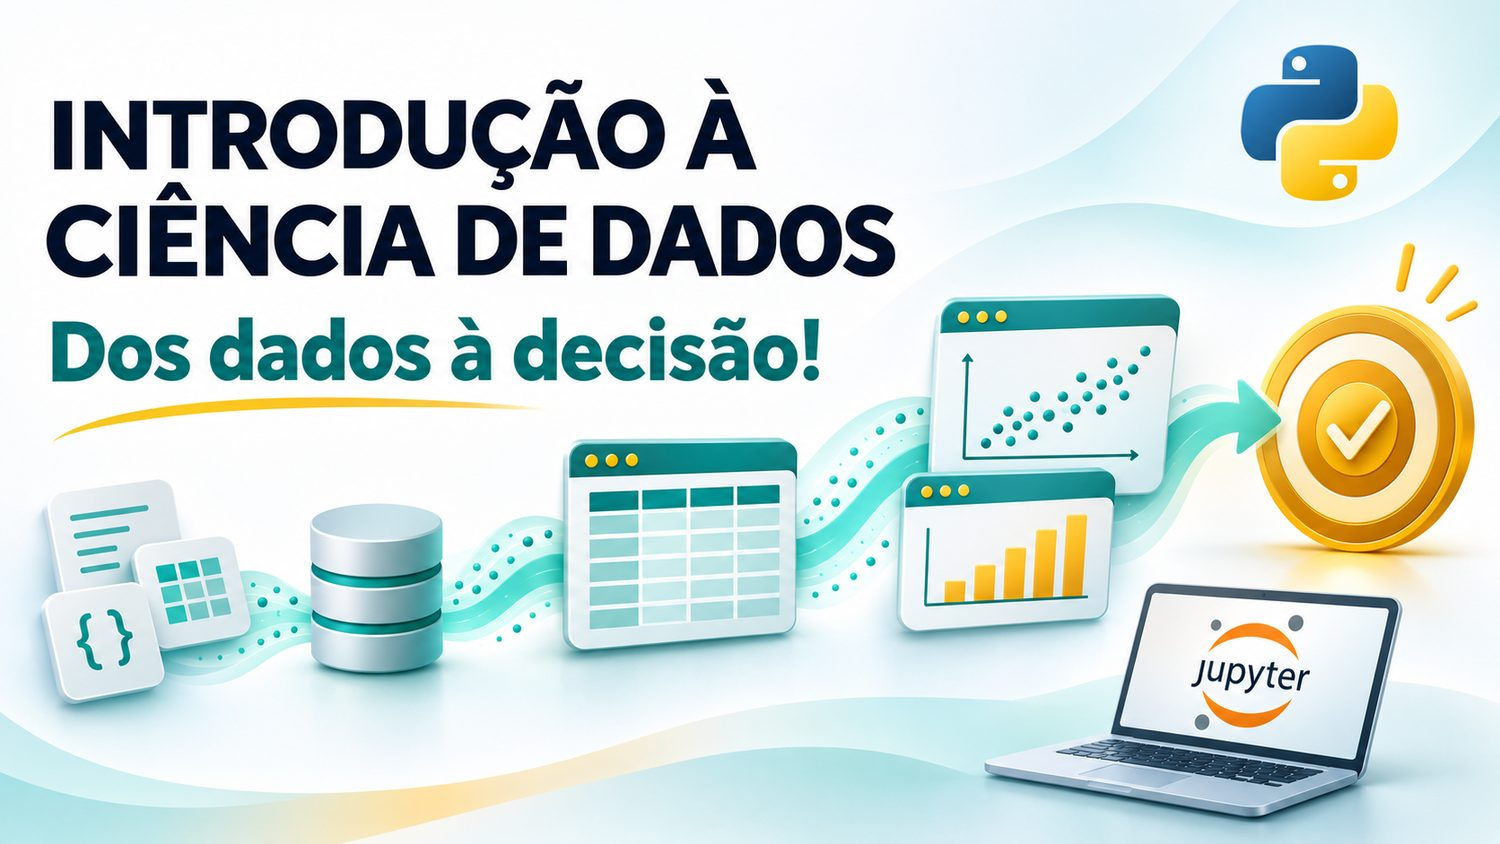

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_3_explorar_os_dados/02_Agrupar_e_Remodelar.ipynb)

# Capítulo 2 – Agrupar e remodelar

Dez mil linhas não se leem. Para perceber o que os dados dizem é preciso resumi-los por grupos e mudar-lhes a forma, conforme a pergunta. Este capítulo trata das duas operações que mais se usam em análise exploratória: agrupar e remodelar.

> **Objetivos:** distinguir dados transversais, séries temporais e dados em painel; aplicar o padrão dividir–aplicar–combinar com `groupby`; distinguir agregar de transformar; passar do formato longo para o largo e vice-versa; juntar tabelas para comparar grupos de forma justa.

**Pré-requisitos:** capítulo 1 deste módulo. Para a sintaxe em detalhe: [Pandas intermédio](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_01_Pandas_Intermedio.ipynb) e [Pandas avançado](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_02_Pandas_Avancado.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_escolas(semente=11):
    """Gera o consumo diário de eletricidade de 30 escolas fictícias durante um ano letivo (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    n = 30
    tipo = rng.choice(["básica", "secundária"], n, p=[0.6, 0.4])
    alunos = np.where(tipo == "básica", rng.integers(120, 520, n), rng.integers(450, 1400, n))
    escolas = pd.DataFrame({
        "escola_id": [f"E{i:02d}" for i in range(1, n + 1)],
        "tipo": tipo,
        "alunos": alunos,
        "area_m2": (alunos * rng.normal(9.0, 1.2, n)).round(-1).astype(int),
        "ano_construcao": rng.integers(1965, 2016, n),
        "paineis_solares": rng.random(n) < 0.3})
    dias = pd.date_range("2025-09-01", "2026-08-31", freq="D")
    dia_do_ano = dias.dayofyear.to_numpy()
    temperatura = 16.5 + 7.5 * np.cos(2 * np.pi * (dia_do_ano - 205) / 365) + rng.normal(0, 2.2, len(dias))
    ferias = (((dias >= "2025-12-20") & (dias <= "2026-01-04")) | ((dias >= "2026-03-28") & (dias <= "2026-04-12"))
              | (dias >= "2026-07-01"))
    meteo = pd.DataFrame({"data": dias, "temperatura": temperatura.round(1), "ferias": ferias})
    tabelas = []
    for e in escolas.itertuples():
        base = 0.55 * e.alunos + 0.012 * e.area_m2 * (1.25 if e.ano_construcao < 1990 else 1.0)
        aquecimento = 1 + 0.045 * np.clip(15 - temperatura, 0, None)
        ocupacao = np.where(dias.dayofweek >= 5, 0.22, 1.0) * np.where(ferias, 0.30, 1.0)
        sol = np.clip(0.5 + 0.5 * np.cos(2 * np.pi * (dia_do_ano - 172) / 365), 0, 1)
        solar = 1 - (0.28 * sol if e.paineis_solares else 0)
        kwh = base * aquecimento * np.maximum(ocupacao, 0.08) * solar * rng.lognormal(0, 0.10, len(dias))
        avarias = rng.random(len(dias)) < 0.004                     # dias com um consumo anormal
        kwh = np.where(avarias, kwh * rng.uniform(2.5, 4.0, len(dias)), kwh)
        tabelas.append(pd.DataFrame({"escola_id": e.escola_id, "data": dias, "kwh": kwh.round(1)}))
    return escolas, pd.concat(tabelas, ignore_index=True), meteo


escolas, consumo, meteo = gerar_escolas()
consumo.head()

,escola_id,data,kwh
0,E01,2025-09-01,300.5
1,E01,2025-09-02,264.6
2,E01,2025-09-03,265.0
3,E01,2025-09-04,270.0
4,E01,2025-09-05,303.9


## Três formas de olhar para os mesmos dados

A tabela `consumo` tem duas dimensões: **quem** (a escola) e **quando** (o dia). Conforme a dimensão que se fixa, obtêm-se três tipos de dados.

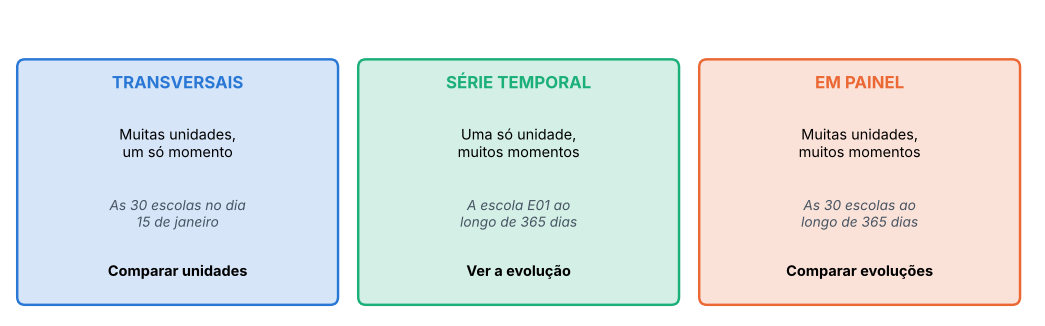

In [3]:
fig, ax = tela(13.2, 3.9, (12, 3.6))
tipos = [("TRANSVERSAIS", "Muitas unidades,\num só momento", "As 30 escolas no dia\n15 de janeiro", "Comparar unidades", AZUL),
         ("SÉRIE TEMPORAL", "Uma só unidade,\nmuitos momentos", "A escola E01 ao\nlongo de 365 dias", "Ver a evolução", VERDE),
         ("EM PAINEL", "Muitas unidades,\nmuitos momentos", "As 30 escolas ao\nlongo de 365 dias", "Comparar evoluções", LARANJA)]
for i, (nome, definicao, exemplo, serve, cor) in enumerate(tipos):
    x = 0.1 + i * 4.4
    caixa(ax, x, 0.15, 4.1, 3.1, "", cor)
    ax.text(x + 2.05, 2.9, nome, ha="center", fontweight="bold", color=cor, fontsize=11)
    ax.text(x + 2.05, 2.2, definicao, ha="center", va="center", fontsize=9.5)
    ax.text(x + 2.05, 1.3, exemplo, ha="center", va="center", fontsize=9, color="#465463", style="italic")
    ax.text(x + 2.05, 0.5, serve, ha="center", fontsize=9.5, fontweight="bold")
plt.show()

In [4]:
um_dia = consumo[consumo["data"] == "2026-01-15"]
uma_escola = consumo[consumo["escola_id"] == "E01"]
print(f"Transversal:    {len(um_dia):>6} linhas (30 escolas × 1 dia)")
print(f"Série temporal: {len(uma_escola):>6} linhas (1 escola × 365 dias)")
print(f"Painel:         {len(consumo):>6} linhas (30 escolas × 365 dias)")

Transversal:        30 linhas (30 escolas × 1 dia)
Série temporal:    365 linhas (1 escola × 365 dias)
Painel:          10950 linhas (30 escolas × 365 dias)


A dimensão **transversal** compara unidades entre si; a **longitudinal** acompanha cada unidade no tempo. Os dados em painel têm as duas, e por isso permitem perguntas que os outros não permitem: por exemplo, se as escolas com painéis solares baixaram o consumo *mais do que as outras* na primavera.

## Agrupar: dividir, aplicar, combinar

Quase todas as perguntas do tipo «quanto, por cada…» seguem o mesmo padrão em três passos.

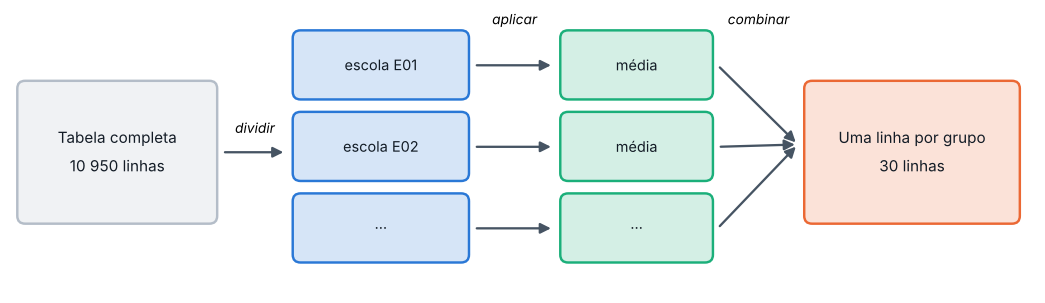

In [5]:
fig, ax = tela(13, 3.6, (12, 3.3))
caixa(ax, 0.1, 0.9, 2.5, 1.8, "Tabela completa\n10 950 linhas", CINZA, 10)
seta(ax, (2.68, 1.8), (3.5, 1.8))
ax.text(3.1, 2.05, "dividir", ha="center", fontsize=9, style="italic")
for k, (rotulo, cor) in enumerate([("escola E01", AZUL), ("escola E02", AZUL), ("…", AZUL)]):
    caixa(ax, 3.6, 2.5 - k * 1.05, 2.2, 0.85, rotulo, cor, 9.5)
    seta(ax, (5.88, 2.92 - k * 1.05), (6.9, 2.92 - k * 1.05))
    caixa(ax, 7.0, 2.5 - k * 1.05, 1.9, 0.85, "média" if k < 2 else "…", VERDE, 9.5)
    seta(ax, (8.98, 2.92 - k * 1.05), (10.0, 1.9))
ax.text(6.4, 3.45, "aplicar", ha="center", fontsize=9, style="italic")
ax.text(9.5, 3.45, "combinar", ha="center", fontsize=9, style="italic")
caixa(ax, 10.1, 0.9, 2.7, 1.8, "Uma linha por grupo\n30 linhas", LARANJA, 10)
plt.show()

In [6]:
por_escola = consumo.groupby("escola_id")["kwh"].mean()
print(por_escola.head(), "\n")
print("Linhas:", len(consumo), "→", len(por_escola))

escola_id
E01    210.271507
E02    125.679178
E03    556.449041
E04     94.519452
E05     54.900274
Name: kwh, dtype: float64 

Linhas: 10950 → 30


`groupby("escola_id")` divide; `["kwh"].mean()` aplica a média a cada grupo e combina os resultados. O que se põe dentro de `groupby` define a **unidade de análise** do resultado: aqui, a escola.

### Várias medidas e vários grupos

In [7]:
resumo = consumo.groupby("escola_id")["kwh"].agg(dias="count", media="mean", mediana="median", maximo="max").round(1)
resumo.head()

,dias,media,mediana,maximo
escola_id,,,,
E01,365,210.3,264.5,1172.1
E02,365,125.7,141.4,315.7
E03,365,556.4,710.3,1301.6
E04,365,94.5,104.1,676.8
E05,365,54.9,60.4,341.9


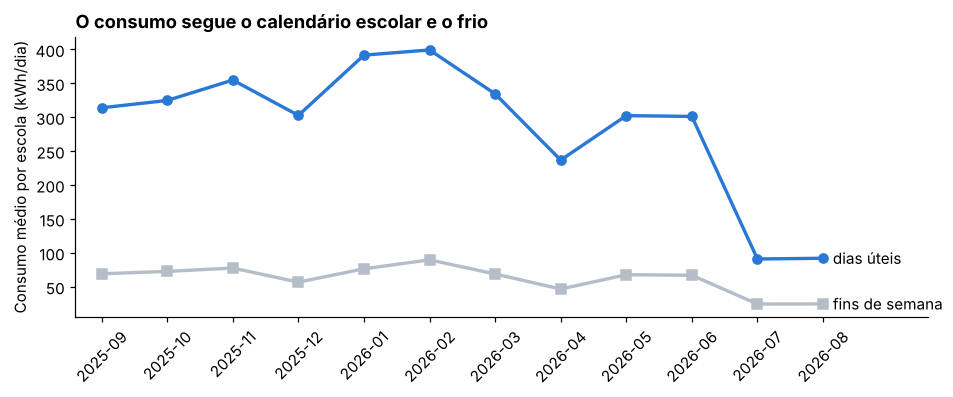

In [8]:
consumo["mes"] = consumo["data"].dt.to_period("M")
consumo["fim_de_semana"] = consumo["data"].dt.dayofweek >= 5
por_mes = consumo.groupby(["mes", "fim_de_semana"])["kwh"].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 3.3))
ax.plot(por_mes.index.astype(str), por_mes[False], color=AZUL, lw=2.2, marker="o")
ax.plot(por_mes.index.astype(str), por_mes[True], color=CINZA, lw=2.2, marker="s")
ax.text(11.15, por_mes[False].iloc[-1], "dias úteis", va="center")
ax.text(11.15, por_mes[True].iloc[-1], "fins de semana", va="center")
ax.set_xlim(-0.4, 12.6)
ax.set_ylabel("Consumo médio por escola (kWh/dia)")
ax.set_title("O consumo segue o calendário escolar e o frio")
ax.tick_params(axis="x", rotation=45)
plt.show()

Com duas chaves no `groupby`, cada combinação de mês e tipo de dia é um grupo. O gráfico mostra três coisas de uma vez: o consumo sobe no inverno, cai nas férias de verão e é sempre muito mais baixo ao fim de semana.

### Agregar ou transformar?

Há duas coisas diferentes que se podem fazer a um grupo.

| Operação | Resultado | Exemplo |
| --- | --- | --- |
| **Agregar** (`agg`, `mean`, `sum`…) | Uma linha por grupo | A média de cada escola |
| **Transformar** (`transform`) | O mesmo número de linhas da tabela original | Cada dia comparado com a média da sua escola |

In [9]:
consumo["media_da_escola"] = consumo.groupby("escola_id")["kwh"].transform("mean")
consumo["relativo"] = consumo["kwh"] / consumo["media_da_escola"]
print(consumo[["escola_id", "data", "kwh", "media_da_escola", "relativo"]].head(3).round({"media_da_escola": 1, "relativo": 2}), "\n")

anormais = consumo[consumo["relativo"] > 4].sort_values("relativo", ascending=False)
print(f"Dias com mais de quatro vezes a média da própria escola: {len(anormais)}")
anormais[["escola_id", "data", "kwh", "relativo"]].head(5).round({"relativo": 1})

  escola_id       data    kwh  media_da_escola  relativo
0       E01 2025-09-01  300.5            210.3      1.43
1       E01 2025-09-02  264.6            210.3      1.26
2       E01 2025-09-03  265.0            210.3      1.26 

Dias com mais de quatro vezes a média da própria escola: 21


,escola_id,data,kwh,relativo
7793,E22,2026-01-07,439.1,7.4
1245,E04,2026-01-29,676.8,7.2
4145,E12,2026-01-09,523.4,6.9
5209,E15,2025-12-09,446.1,6.7
5534,E16,2025-10-30,1455.9,6.5


`transform` devolve um valor por linha, alinhado com a tabela original. É a ferramenta certa para comparar cada observação com o seu grupo: 600 kWh é normal numa escola secundária grande e é um alarme numa básica pequena. A coluna `relativo` põe todas as escolas na mesma escala.

## Remodelar: formato longo e formato largo

A mesma informação pode estar arrumada de duas maneiras.

| Formato | Aspeto | Bom para |
| --- | --- | --- |
| **Longo** | Uma linha por observação; uma coluna diz a que grupo pertence | Guardar, filtrar, agrupar, fazer gráficos |
| **Largo** | Uma linha por unidade; uma coluna por momento ou categoria | Ler, comparar lado a lado, calcular entre colunas |

A tabela `consumo` está no formato longo. Com `pivot_table` passa a largo.

In [10]:
largo = consumo.pivot_table(index="escola_id", columns="mes", values="kwh", aggfunc="mean").round(0)
print("Forma:", largo.shape, "(escolas × meses)")
largo.iloc[:4, :6]

Forma: (30, 12) (escolas × meses)


mes,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02
escola_id,,,,,,
E01,235.0,242.0,234.0,220.0,266.0,276.0
E02,140.0,155.0,159.0,144.0,183.0,183.0
E03,651.0,651.0,643.0,582.0,677.0,787.0
E04,101.0,114.0,111.0,114.0,152.0,141.0


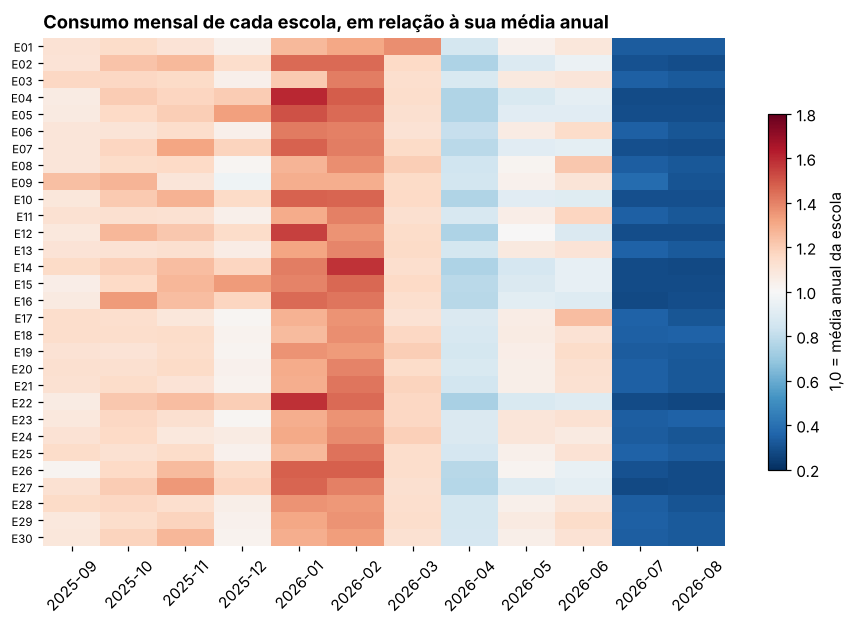

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
relativo = largo.div(largo.mean(axis=1), axis=0)             # cada escola em relação à sua própria média
imagem = ax.imshow(relativo, cmap="RdBu_r", vmin=0.2, vmax=1.8, aspect="auto")
ax.set_xticks(range(12), [str(m) for m in largo.columns], rotation=45)
ax.set_yticks(range(30), largo.index, fontsize=7.5)
ax.set_title("Consumo mensal de cada escola, em relação à sua média anual")
fig.colorbar(imagem, ax=ax, shrink=0.7, label="1,0 = média anual da escola")
ax.spines[:].set_visible(False)
plt.show()

O formato largo torna visível o padrão comum (colunas vermelhas no inverno, azuis em julho e agosto) e as exceções: algumas escolas ficam claramente mais azuis de abril a junho. São as que têm painéis solares.

O caminho inverso, de largo para longo, faz-se com `melt`.

In [12]:
de_volta = largo.reset_index().melt(id_vars="escola_id", var_name="mes", value_name="kwh_medio")
print("Forma:", de_volta.shape)
de_volta.head(4)

Forma: (360, 3)


,escola_id,mes,kwh_medio
0,E01,2025-09,235.0
1,E02,2025-09,140.0
2,E03,2025-09,651.0
3,E04,2025-09,101.0


> **Regra prática:** guarda e trabalha os dados no formato longo; passa a largo no fim, para apresentar ou para comparar colunas.

## Juntar para comparar de forma justa

As escolas maiores gastam mais. Comparar totais não diz quem gasta **bem**. Para isso é preciso juntar as características de cada escola e dividir.

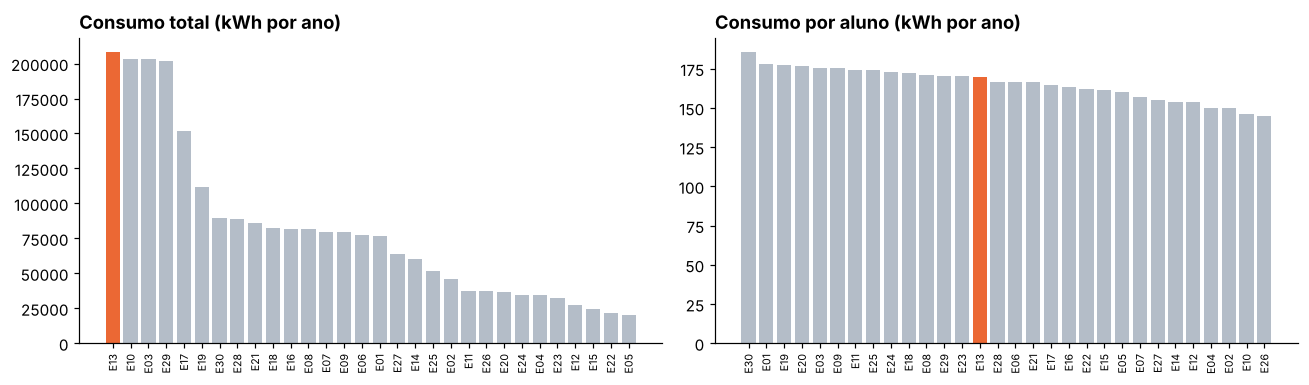

A escola que mais gasta no total (E13) fica em 14.º lugar no consumo por aluno.


In [13]:
anual = consumo.groupby("escola_id")["kwh"].sum().rename("kwh_ano").reset_index()
anual = anual.merge(escolas, on="escola_id", validate="one_to_one")
anual["kwh_por_aluno"] = anual["kwh_ano"] / anual["alunos"]

ordem_total = anual.sort_values("kwh_ano", ascending=False)["escola_id"].tolist()
ordem_aluno = anual.sort_values("kwh_por_aluno", ascending=False)["escola_id"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, coluna, titulo in [(ax1, "kwh_ano", "Consumo total (kWh por ano)"), (ax2, "kwh_por_aluno", "Consumo por aluno (kWh por ano)")]:
    t = anual.sort_values(coluna, ascending=False)
    ax.bar(t["escola_id"], t[coluna], color=[LARANJA if e == ordem_total[0] else CINZA for e in t["escola_id"]])
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
plt.tight_layout()
plt.show()

print(f"A escola que mais gasta no total ({ordem_total[0]}) fica em {ordem_aluno.index(ordem_total[0]) + 1}.º lugar no consumo por aluno.")

A mesma escola, a laranja, aparece nos dois gráficos. Ser a que mais gasta no total diz sobretudo que é grande. A medida por aluno é uma **taxa**, e é a que permite comparar.

In [14]:
comparacao = anual.groupby(["tipo", "paineis_solares"])["kwh_por_aluno"].agg(escolas="count", media="mean").round(0)
comparacao

escolas  media
tipo       paineis_solares                
básica     False                  9  175.0
           True                  10  155.0
secundária False                  9  170.0
           True                   2  155.0

Esta tabela junta tudo o que o capítulo ensinou: uma agregação (o total anual por escola), uma junção (com as características), uma taxa (por aluno) e um novo agrupamento (por tipo e por painéis).

Repara na coluna `escolas`: alguns grupos têm poucas. Uma média de três ou quatro escolas muda muito se uma delas for invulgar. **Mostra sempre quantas observações tem cada grupo.**

## Exercícios

### `Exercício 1` – Que tipo de dados é?

Classifica como transversais, série temporal ou em painel:

1. A temperatura registada todos os dias numa estação meteorológica durante dez anos.
2. Os resultados de um inquérito feito a 2 000 pessoas em maio.
3. As vendas mensais de cada uma das 40 lojas de uma cadeia, de 2020 a 2025.
4. As notas finais de todos os alunos de uma turma.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Série temporal.
2. Transversais.
3. Em painel.
4. Transversais.

</details>

### `Exercício 2` – O dia da semana

Calcula o consumo médio por dia da semana e mostra-o num gráfico de barras. Depois repete, separando as escolas básicas das secundárias (vais precisar de juntar a tabela `escolas`).

In [15]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
nomes = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
t = consumo.merge(escolas[["escola_id", "tipo"]], on="escola_id")
t["dia"] = t["data"].dt.dayofweek
por_dia = t.groupby(["dia", "tipo"])["kwh"].mean().unstack()
por_dia.index = nomes
por_dia.plot.bar(figsize=(7, 3), color=[AZUL, LARANJA], rot=0, ylabel="kWh por dia")
plt.show()
```

O padrão é igual nos dois tipos: cinco dias parecidos e uma queda forte ao fim de semana. As secundárias gastam mais em todos os dias porque têm mais alunos.

</details>

### `Exercício 3` – Agregar ou transformar?

Indica qual das duas usarias, e escreve o código da segunda:

1. O consumo máximo de cada escola.
2. Para cada dia, a diferença entre o consumo e a mediana do mesmo mês nessa escola.
3. O número de dias de férias em cada mês.

In [16]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Agregar: uma linha por escola.
2. Transformar: o resultado tem uma linha por dia.
3. Agregar.

```python
mediana = consumo.groupby(["escola_id", "mes"])["kwh"].transform("median")
consumo["desvio_da_mediana"] = consumo["kwh"] - mediana
consumo[["escola_id", "data", "kwh", "desvio_da_mediana"]].head()
```

</details>

### `Exercício 4` – Largo e longo

Constrói uma tabela no formato largo com uma linha por mês e duas colunas: o consumo médio das escolas com painéis solares e o das escolas sem painéis. Acrescenta uma terceira coluna com a razão entre as duas. Em que meses é maior a diferença?

In [17]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
t = consumo.merge(escolas[["escola_id", "paineis_solares", "alunos"]], on="escola_id")
t["por_aluno"] = t["kwh"] / t["alunos"]
tabela = t.pivot_table(index="mes", columns="paineis_solares", values="por_aluno", aggfunc="mean")
tabela.columns = ["sem_paineis", "com_paineis"]
tabela["razao"] = tabela["com_paineis"] / tabela["sem_paineis"]
tabela.round(3)
```

A razão é mais baixa de maio a julho, quando há mais sol. É preciso comparar o consumo **por aluno**: se as escolas com painéis forem, por acaso, maiores ou mais pequenas do que as outras, a comparação dos valores absolutos mistura os dois efeitos.

</details>

## Verifica o que aprendeste

- [ ] Sei distinguir dados transversais, séries temporais e dados em painel.
- [ ] Sei explicar o padrão dividir–aplicar–combinar.
- [ ] Sei agrupar por uma ou várias chaves e calcular várias medidas.
- [ ] Sei quando usar `agg` e quando usar `transform`.
- [ ] Sei passar do formato longo para o largo (`pivot_table`) e de volta (`melt`).
- [ ] Sei porque se comparam taxas e não totais.

## Leitura recomendada

- https://pandas.pydata.org/docs/user_guide/groupby.html
- https://pandas.pydata.org/docs/user_guide/reshaping.html
- https://en.wikipedia.org/wiki/Panel_data